# **English to España Translation ML Model**
**(English-to-Spanish Neural Machine Translation using Attention-Based Seq2Seq LSTM)**

**Import Libraries**

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import unicodedata
from wordcloud import WordCloud
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import (
    Input, Embedding, LSTM, Dense,
    Bidirectional, Attention, Concatenate
)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

print(tf.__version__)
print(len(tf.config.list_physical_devices('GPU')) > 0)

2.21.0
True


**Import Dataset**

In [5]:
from google.colab import files
uploaded = files.upload()

Saving english-spanish-dataset.csv to english-spanish-dataset.csv


In [6]:
data = pd.read_csv('english-spanish-dataset.csv')

In [7]:
data.head()

,Unnamed: 0,english,spanish
0,0,go,ve
1,1,go,vete
2,2,go,vaya
3,3,go,vayase
4,4,hi,hola


In [8]:
data.shape

(120614, 3)

In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120614 entries, 0 to 120613
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   Unnamed: 0  120614 non-null  int64 
 1   english     120614 non-null  object
 2   spanish     120614 non-null  object
dtypes: int64(1), object(2)
memory usage: 2.8+ MB


In [10]:
data.isna().sum()     # Checking for any null values

,0
Unnamed: 0,0
english,0
spanish,0


In [11]:
print('Duplicate values in dataset:',data.duplicated().sum())     # Checking for duplicate values

Duplicate values in dataset: 0


In [12]:
data = data[['english', 'spanish']]    # Saving only Necessary Columns

In [13]:
data['english_length'] = data['english'].astype(str).str.len()     # Counts english characters
data['spanish_length'] = data['spanish'].astype(str).str.len()     # Counts spanish characters

In [14]:
data.head()

,english,spanish,english_length,spanish_length
0,go,ve,2,2
1,go,vete,2,4
2,go,vaya,2,4
3,go,vayase,2,6
4,hi,hola,2,4


### **Data Cleaning**

In [15]:
# Removing rows with empty english and spanish sentences
data = data[data['english'] != '']
data = data[data['spanish'] != '']

# Cleaning function
def clean_text(text):
  text = str(text)                    # Converting input text into a string
  text = unicodedata.normalize('NFC',text)    # Normalize unicode characters while preserving spanish accents
  text = text.strip()              # Removing unecessary leading and trailing spaces
  text = re.sub(r'\s+',' ',text)      # removing multiple spaces, tabs, newlines with single space
  return text

data['english'] = data['english'].apply(clean_text)    # Apply clean function to 'english' column
data['spanish'] = data['spanish'].apply(clean_text)    # Apply clean function to 'spanish' column

In [16]:
data.duplicated().sum()

np.int64(277)

In [17]:
# Displaying those duplicate rows identified after applying cleaning function
data[data.duplicated(keep=False)].sort_values(
    by=['english', 'spanish']
).head(4)

,english,spanish,english_length,spanish_length
86003,art is not a luxury but a necessity,el arte no es un lujo sino una necesidad,35,40
86004,art is not a luxury but a necessity,el arte no es un lujo sino una necesidad,35,40
12833,ask the policeman,preguntale al policia,17,21
12834,ask the policeman,preguntale al policia,17,21


In [18]:
data.drop_duplicates(inplace=True)      # Dropping duplicates
data.duplicated().sum()

np.int64(0)

In [19]:
data.reset_index(drop=True, inplace=True)    # Resetting index

# **Exploratory Data Analysis (EDA)**
## **Histogram Visualization**

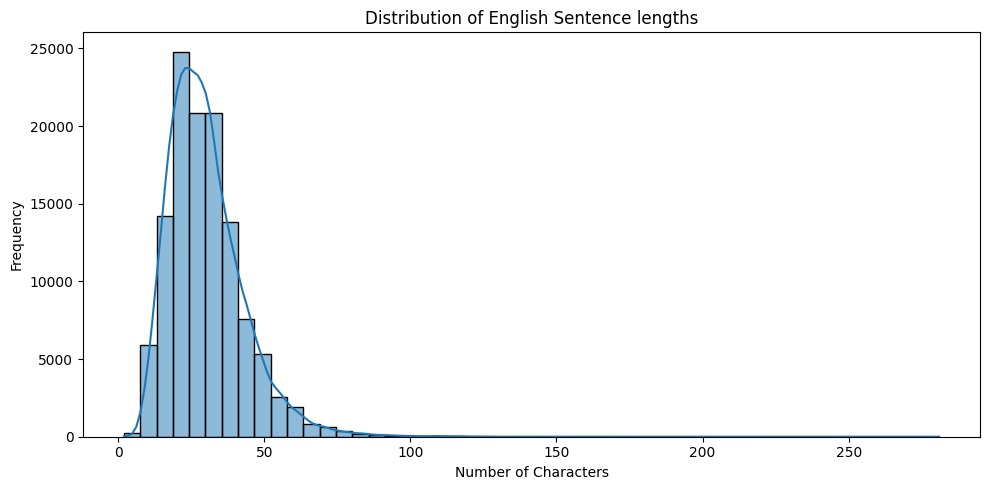

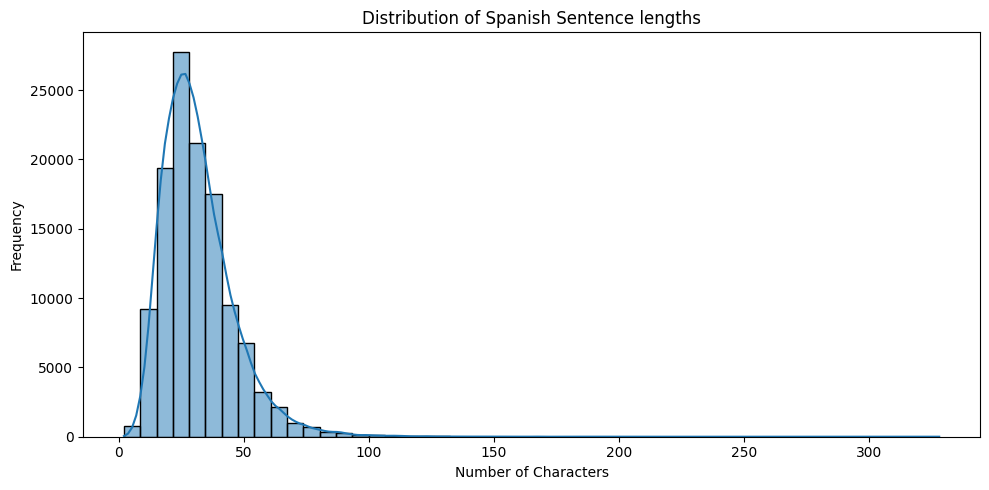

In [20]:
# Some EDA of distribution of character lengths across both languages
plt.figure(figsize=(10, 5))
sns.histplot(data['english_length'], bins=50, kde=True)
plt.title('Distribution of English Sentence lengths')
plt.xlabel('Number of Characters')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.histplot(data['spanish_length'], bins=50, kde=True)
plt.title('Distribution of Spanish Sentence lengths')
plt.xlabel('Number of Characters')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

## **WordCloud Visualization**

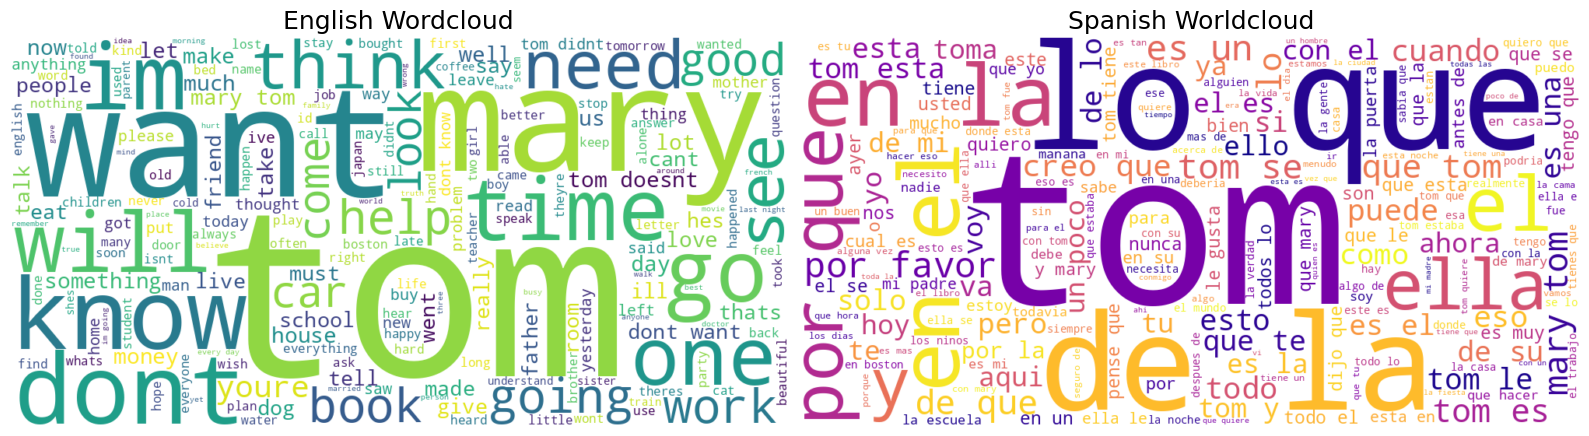

In [21]:
# Combining all english and spanish sentences
english_text = ' '.join(data['english'].dropna())
spanish_text = ' '.join(data['spanish'].dropna())

# Creating English Wordcloud
english_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    colormap='viridis'
).generate(english_text)

# Creating Spanish Wordcloud
spanish_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    colormap='plasma'
).generate(spanish_text)

plt.figure(figsize=(16,7))

plt.subplot(1, 2, 1)
plt.imshow(english_wordcloud, interpolation='bilinear')
plt.title('English Wordcloud', fontsize=18)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(spanish_wordcloud, interpolation='bilinear')
plt.title('Spanish Worldcloud', fontsize=18)
plt.axis('off')

plt.tight_layout()
plt.show()


## **Data Preprocessing**

In [22]:
data['encoder_input'] = data['english']
data['decoder_input'] = '<start> ' + data['spanish']      # Adds "<start>" before every spanish sentence
data['decoder_target'] = data['spanish'] + ' <end>'       # Adds "<end>" after every spanish sentence

data['english_word_count'] = data['english'].apply(lambda x: len(x.split()))     # Counts english words
data['spanish_word_count'] = data['spanish'].apply(lambda x: len(x.split()))     # Counts spanish words

In [23]:
data['decoder_input'].head()

,decoder_input
0,<start> ve
1,<start> vete
2,<start> vaya
3,<start> vayase
4,<start> hola


In [24]:
data['decoder_target'].head()

,decoder_target
0,ve <end>
1,vete <end>
2,vaya <end>
3,vayase <end>
4,hola <end>


In [25]:
# Shows statistical metrics of this column
data['english_word_count'].describe()

,english_word_count
count,120337.000000
mean,6.305135
std,2.607563
min,1.000000
25%,4.000000
50%,6.000000
75%,8.000000
max,47.000000


In [26]:
# Shows statistical metrics of this column
data['spanish_word_count'].describe()

,spanish_word_count
count,120337.000000
mean,6.076892
std,2.760247
min,1.000000
25%,4.000000
50%,6.000000
75%,7.000000
max,53.000000


# **Data Preparation**

In [27]:
x = data['english']
y = data['spanish']

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

print('x_train:', x_train.shape[0])
print('y_train:', y_train.shape[0])
print('x_test:', x_test.shape[0])
print('y_test:', y_test.shape[0])

x_train: 96269
y_train: 96269
x_test: 24068
y_test: 24068


## **Text Preprocessing**
**TOKENIZATION**

In [28]:
english_tokenizer = Tokenizer(oov_token='<unk>', filters='')    # Creates english tokenizer that converts english words into numerical indexes
spanish_tokenizer = Tokenizer(oov_token='<unk>', filters='')    # Creates same tokenizer but for spanish

# Fitting english tokenizer on training data only
english_tokenizer.fit_on_texts(x_train)            # fit_on_texts() scans through all the sentences in x_train and identify words, counts, assign integer index to each word

# Usage of 'teacher forcing' technique
y_train_decoder_input = '<start> ' + y_train.astype(str)   # Converting spanish training sentences into strings and adds <start> at the beginning
y_train_decoder_target = y_train.astype(str) + ' <end>'    # Adds <end> at the end of every spanish training sentence

# Combines spanish decoder inputs and targets into one list and
# Fitting spanish tokenizer on training data only
spanish_tokenizer.fit_on_texts(
    list(y_train_decoder_input) + list(y_train_decoder_target)
)

# Converting english training and testing sentences into numerical sequences
x_train_sequences = english_tokenizer.texts_to_sequences(x_train)
x_test_sequences = english_tokenizer.texts_to_sequences(x_test)

# Converting spanish training (decoder input & decoder target) sentences into numerical sequences respectively
y_train_input_sequences = spanish_tokenizer.texts_to_sequences(y_train_decoder_input)
y_train_target_sequences = spanish_tokenizer.texts_to_sequences(y_train_decoder_target)

# Finding maximum sequence lengths from english training data
max_english_length = max(len(seq) for seq in x_train_sequences)

# Finding maximum sequence lengths from both training decoder inputs and decoder targets data
max_spanish_length = max(
   max(len(seq) for seq in y_train_input_sequences),
   max(len(seq) for seq in y_train_target_sequences)
)

# Applying padding to english training data
x_train_padded = pad_sequences(
    x_train_sequences,
    maxlen=max_english_length,
    padding='post'      # Adds zeros at the end of the sequences
)

# Applying padding to english testing data
x_test_padded = pad_sequences(
    x_test_sequences,
    maxlen=max_english_length,
    padding='post'
)

# Applying padding to spanish decoder inputs
y_train_input_padded = pad_sequences(
    y_train_input_sequences,
    maxlen=max_spanish_length,
    padding='post'
)

# Applying padding to spanish decoder targets
y_train_target_padded = pad_sequences(
    y_train_target_sequences,
    maxlen=max_spanish_length,
    padding='post'
)

# Calculating Vocabulary Sizes
english_vocab_size = len(english_tokenizer.word_index) + 1
spanish_vocab_size = len(spanish_tokenizer.word_index) + 1

print('English vocabulary size:',english_vocab_size)
print('Spanish vocabulary size:',spanish_vocab_size)
print()
print('Maximum English sequence length:',max_english_length)
print('Maximum Spanish sequence length:',max_spanish_length)
print()
print('English training shape:',x_train_padded.shape)
print('Spanish decoder input shape:',y_train_input_padded.shape)
print('Spanish decoder target shape:', y_train_target_padded.shape)

English vocabulary size: 12451
Spanish vocabulary size: 22737

Maximum English sequence length: 47
Maximum Spanish sequence length: 50

English training shape: (96269, 47)
Spanish decoder input shape: (96269, 50)
Spanish decoder target shape: (96269, 50)


# **Building the Encoder–Decoder Architecture (with Bidirectional LSTM and Attention)**

### **Encoder**
- Receives a padded English sentence.
- Converts word IDs into 128-dimensional embeddings.
- Processes the sentence using a Bidirectional LSTM with 128 units in each direction.
- Produces contextual outputs for every English word.
- Concatenates the forward and backward hidden and cell states to initialize the decoder.

### **Decoder**
- Receives the encoder's hidden and cell states.
- Converts Spanish input word IDs into 128-dimensional embeddings.
- Uses an LSTM with 256 units to generate decoder outputs.
- Applies Attention to focus on relevant English words at each decoding step.
- Concatenates decoder outputs with the attention context.
- Uses a Dense layer with Softmax to predict probabilities for the next Spanish word.

During training, the decoder uses the actual previous Spanish words (teacher forcing) to learn the translation. During inference, it generates words sequentially until the `<end>` token is produced.

This architecture is called **Sequence-to-Sequence Learning with Attention**.

---

### **What is an LSTM?**

An LSTM (Long Short-Term Memory) is a type of recurrent neural network designed to process sequential data.

Unlike a traditional feedforward neural network, it processes data step by step and maintains information from previous steps using its internal memory and gates.

In our project, the LSTM helps the model understand the sequence of English words and retain useful contextual information for translation.

A **Bidirectional LSTM** processes the sentence in both directions forward and backward allowing it to capture context from both sides of each word.

In [29]:
# Encoder

# Defining Encoder input layer
encoder_inputs = Input(
    shape=(max_english_length,),   # 47
    name='encoder_inputs'
)

# Creating the English Embedding layer (to convert English token IDs into dense vectors)
encoder_embedding_layer = Embedding(
    input_dim=english_vocab_size,  # Total number of unique English vocabulary tokens (12451)
    output_dim=128,                # Each word represented by 128-dimensional vector
    mask_zero=True,                # Ignore padding tokens (token ID 0)
    name='encoder_embedding'
)

# Convert the English input token IDs into their corresponding embedding vectors
encoder_embedding = encoder_embedding_layer(encoder_inputs)

# Creating the Bidirectional LSTM encoder
encoder_lstm = Bidirectional(
    LSTM(
        128,                       # Each individual LSTM direction has 128 units
        return_sequences=True,     # Return an output for every English token position
        return_state=True,         # Also return the final hidden and cell states
        dropout=0.2                # Drop 20% of input connections during training to reduce overfitting
    ),
    name='encoder_lstm'
)

# Passing English embeddings through the encoder
# encoder_outputs contains outputs from both directions at every time step
# forward_h and forward_c are the final hidden and cell states of the forward LSTM
# backward_h and backward_c are the final hidden and cell states of the backward LSTM
encoder_outputs, forward_h, forward_c, backward_h, backward_c = encoder_lstm(
    encoder_embedding
)

# Combining the forward and backward states
# Each state has 128 units, so the concatenated state has 256 dimensions
state_h = Concatenate()([forward_h, backward_h])

state_c = Concatenate()([forward_c, backward_c])

# Store the combined hidden and cell states
encoder_states = [state_h, state_c]


# DECODER

# Defining the Spanish decoder input layer
decoder_inputs = Input(
    shape=(max_spanish_length,),  # 50
    name='decoder_inputs'
)

# Creating Spanish Embedding layer (to convert Spanish token IDs into dense vectors)
decoder_embedding_layer = Embedding(
    input_dim=spanish_vocab_size,  # Total number of unique Spanish vocabulary tokens (22737)
    output_dim=128,                # Represent each Spanish token using a 128-dimensional vector
    mask_zero=True,                # Ignore padding tokens (token ID 0)
    name='decoder_embedding'
)

# Convert the Spanish input token IDs into their corresponding embedding vectors
decoder_embedding = decoder_embedding_layer(decoder_inputs)

# Defining the decoder LSTM
decoder_lstm_layer = LSTM(
    256,                           # Use 256 LSTM units to match the combined encoder state dimensions
    return_sequences=True,         # Return an output for every Spanish input time step
    return_state=True,             # Also return the final hidden and cell states
    dropout=0.2,                    # Drop 20% of input connections during training to reduce overfitting
    name='decoder_lstm'
)

# Passing Spanish embeddings through the decoder LSTM
# Initialize its hidden and cell states using the encoder's final states
# The decoder learns to generate Spanish representations using the English context
# The final two returned states are ignored here because only the sequence outputs are needed
decoder_outputs, _, _ = decoder_lstm_layer(
    decoder_embedding,
    initial_state=encoder_states
)


#  ATTENTION LAYER

# Defining the Attention layer
attention_layer = Attention(
    use_scale=True,                # Learn a scaling factor for the attention similarity scores
    name='attention'
)

# Calculating attention context
attention_context = attention_layer([
    decoder_outputs,               # act as the queries
    encoder_outputs                # act as the values and keys in this Keras attention implementation
])

# Combining Decoder Representations with Attention Context
decoder_combined_context = Concatenate(axis=-1)([
    decoder_outputs,               # Decoder representations (256 dimensions)
    attention_context               # Attention context vectors (256 dimensions)
])


#  OUTPUT LAYER

# Define a Dense layer to predict the probability of each Spanish vocabulary token
decoder_dense = Dense(
    spanish_vocab_size,            # Produce one probability score for every Spanish vocabulary token
    activation='softmax',          # Convert scores into probabilities that sum to 1
    name='decoder_dense'
)

# Generating Spanish Token Probabilities
decoder_outputs = decoder_dense(decoder_combined_context)


# Building the complete encoder-decoder model

# Connect the encoder and decoder into one end-to-end training model
model = Model(
    inputs=[encoder_inputs, decoder_inputs],  # Accept English input and Spanish decoder input
    outputs=decoder_outputs                   # Predict Spanish vocabulary probabilities at each time step
)

# Display the model architecture, including layers, output shapes, and parameter counts
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_inputs      │ (None, 47)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_embedding   │ (None, 47, 128)   │  1,593,728 │ encoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 47)        │          0 │ encoder_inputs[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_inputs      │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm        │ [(None, 47, 256), │    263,168 │ encoder_embeddin… │
│ (Bidirectional)     │ (None, 128),      │            │ not_equal[0][0]   │
│                     │ (None, 128),      │            │                   │
│                     │ (None, 128),      │            │                   │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_embedding   │ (None, 50, 128)   │  2,910,336 │ decoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 256)       │          0 │ encoder_lstm[0][… │
│ (Concatenate)       │                   │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 256)       │          0 │ encoder_lstm[0][… │
│ (Concatenate)       │                   │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, 50, 256), │    394,240 │ decoder_embeddin… │
│                     │ (None, 256),      │            │ concatenate[0][0… │
│                     │ (None, 256)]      │            │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ (None, 50, 256)   │          1 │ decoder_lstm[0][… │
│ (Attention)         │                   │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 50, 512)   │          0 │ decoder_lstm[0][… │
│ (Concatenate)       │                   │            │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dense       │ (None, 50, 22737) │ 11,664,081 │ concatenate_2[0]… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 16,825,554 (64.18 MB)

 Trainable params: 16,825,554 (64.18 MB)

 Non-trainable params: 0 (0.00 B)

### **What are Parameters?**

Parameters are the learnable numerical values in a neural network that are adjusted during training to minimize prediction errors. They include weights and biases that help the model learn patterns, relationships, and representations from the training data.

# **Model Training**

In [30]:
# Preparing the training weights
# Preparing Loss Weights to Ignore Padding
y_train_sample_weights = (
    y_train_target_padded != 0   # It creates a weight of 1 for actual Spanish tokens and 0 for padding tokens
).astype('float32')


# Compiling the Model
model.compile(
    optimizer='adam',                    # Use the Adam optimizer to update model weights during training
    loss='sparse_categorical_crossentropy'  # Calculate prediction error using integer-encoded target token IDs
)


# Create an EarlyStopping callback (to prevent unnecessary training and reduce overfitting)
early_stopping = EarlyStopping(
    monitor='val_loss',              # Monitor validation loss after every epoch
    patience=4,                      # Stop training if validation loss does not improve for 4 consecutive epochs
    restore_best_weights=True        # Restore the model weights from the epoch with the lowest validation loss
)


# Create a callback that reduces the learning rate when validation loss stops improving
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',              # Monitor validation loss to detect when learning progress has stalled
    factor=0.5,                      # Reduce learning rate to half its current value
    patience=2,                      # Wait for 2 consecutive epochs without improvement before reducing the learning rate
    min_lr=0.00001,                  # Do not allow the learning rate to decrease below 0.00001
    verbose=1                        # Display a message whenever the learning rate is reduced
)

## **Training the English-to-Spanish Model**

In [31]:
history = model.fit(
    [x_train_padded, y_train_input_padded],  # Provide English input sequences and Spanish decoder input sequences
    y_train_target_padded,                   # Provide Spanish target sequences that the model must predict
    sample_weight=y_train_sample_weights,    # Assign 0 weight to padding tokens and 1 to actual target tokens
    batch_size=128,                          # Process 128 training samples in each batch before updating model weights
    epochs=30,                               # Allow the model to train for a maximum of 30 complete passes over the training data
    validation_split=0.1,                    # Reserve 10% of the supplied training data for validation after each epoch
    callbacks=[early_stopping, reduce_lr],   # Apply early stopping and learning rate reduction during training
    verbose=1
)


Epoch 1/30
677/677 ━━━━━━━━━━━━━━━━━━━━ 229s 323ms/step - loss: 5.3013 - val_loss: 4.2354 - learning_rate: 0.0010
Epoch 2/30
677/677 ━━━━━━━━━━━━━━━━━━━━ 226s 334ms/step - loss: 3.4611 - val_loss: 3.0673 - learning_rate: 0.0010
Epoch 3/30
677/677 ━━━━━━━━━━━━━━━━━━━━ 226s 333ms/step - loss: 2.4859 - val_loss: 2.5313 - learning_rate: 0.0010
Epoch 4/30
677/677 ━━━━━━━━━━━━━━━━━━━━ 227s 335ms/step - loss: 1.9233 - val_loss: 2.2702 - learning_rate: 0.0010
Epoch 5/30
677/677 ━━━━━━━━━━━━━━━━━━━━ 227s 335ms/step - loss: 1.5565 - val_loss: 2.1316 - learning_rate: 0.0010
Epoch 6/30
677/677 ━━━━━━━━━━━━━━━━━━━━ 226s 334ms/step - loss: 1.2971 - val_loss: 2.0599 - learning_rate: 0.0010
Epoch 7/30
677/677 ━━━━━━━━━━━━━━━━━━━━ 227s 336ms/step - loss: 1.1123 - val_loss: 2.0182 - learning_rate: 0.0010
Epoch 8/30
677/677 ━━━━━━━━━━━━━━━━━━━━ 227s 335ms/step - loss: 0.9817 - val_loss: 1.9893 - learning_rate: 0.0010
Epoch 9/30
677/677 ━━━━━━━━━━━━━━━━━━━━ 227s 336ms/step - loss: 0.8820 - val_loss: 1.984

### **Building Encoder-Decoder Inference Model**

In [32]:
# Creating the Encoder Inference model
encoder_model = Model(
    inputs=encoder_inputs,                 # Accept the padded English input sequence
    outputs=[encoder_outputs, state_h, state_c]  # Return encoder outputs for attention and final hidden and cell states for initializing the decoder
)

# Decoder Inference Inputs
# Define an input to receive the previous decoder hidden state
decoder_state_input_h = Input(
    shape=(256,),                          # Hidden state contains 256 values, matching the decoder LSTM units
    name='decoder_state_input_h'
)

# Define an input to receive the previous decoder cell state
decoder_state_input_c = Input(
    shape=(256,),                          # Cell state contains 256 values, matching the decoder LSTM units
    name='decoder_state_input_c'
)

# Defining the single-token decoder input
decoder_single_input = Input(
    shape=(1,),                            # Accept exactly one Spanish token ID per decoding step
    name='decoder_single_input'
)

# Defining the encoder output input
encoder_output_input = Input(
    shape=(max_english_length, 256),       # Each English time step has a 256-dimensional bidirectional encoder output
    name='encoder_output_input'
)

# Creating the Encoder Padding Mask for Attention
encoder_mask_input = Input(
    shape=(max_english_length,),           # One Boolean mask value for every English input position
    dtype='bool',                          # Specify that the mask contains Boolean True/False values
    name='encoder_mask_input'
)


# Decoder Token Embedding During Inference
# Convert the current Spanish token ID into its 128-dimensional embedding vector
decoder_single_embedding = decoder_embedding_layer(
    decoder_single_input
)


# Decoder LSTM During Inference

# Process the current Spanish token using the decoder LSTM
decoder_single_outputs, state_h, state_c = decoder_lstm_layer(
    decoder_single_embedding,
    initial_state=[
        decoder_state_input_h,             # Previous decoder hidden state
        decoder_state_input_c              # Previous decoder cell state
    ]
)


#  ATTENTION During Token-by-Token Translation

# Calculate attention between the current decoder output and all encoder outputs
attention_single_context = attention_layer(
    [
        decoder_single_outputs,
        encoder_output_input
    ],
    mask=[
        None,
        encoder_mask_input
    ]
)

# Combining Decoder Output and Attention Context During Inference
decoder_single_combined = Concatenate(axis=-1)([
    decoder_single_outputs,
    attention_single_context
])


# Spanish Token Prediction During Inference
# Generate a probability distribution over the Spanish vocabulary for the next token
decoder_single_outputs = decoder_dense(
    decoder_single_combined
)

# Building the Decoder Inference Model

# Create the decoder inference model for generating Spanish translations one token at a time
decoder_model = Model(
    inputs=[
        decoder_single_input,              # Current Spanish input token ID
        decoder_state_input_h,             # Previous decoder hidden state
        decoder_state_input_c,             # Previous decoder cell state
        encoder_output_input,              # Full English encoder outputs
        encoder_mask_input                 # Identifies real English tokens and padding
    ],
    outputs=[
        decoder_single_outputs,            # Probability distribution over Spanish vocabulary
        state_h,                           # Updated hidden state for the next decoding step
        state_c                            # Updated cell state for the next decoding step
    ]
)


## **Translation Function**

In [33]:
# Implementing the English-to-Spanish Translation Function
def translate(sentence):

    # Converting the English sentence into numerical form
    input_sequence = english_tokenizer.texts_to_sequences([sentence])

    input_sequence = pad_sequences(
        input_sequence,
        maxlen=max_english_length,
        padding='post'
    )

    # Creating the Input Mask for Attention
    encoder_mask = (input_sequence != 0)

    # Get encoder outputs and states
    encoder_outputs, state_h, state_c = encoder_model.predict(
        input_sequence,
        verbose=0
    )

    states = [state_h, state_c]

    # Retrieving Spanish Start and End Tokens
    start_token = spanish_tokenizer.word_index['<start>']
    end_token = spanish_tokenizer.word_index['<end>']

    # Initializing Spanish Sentence Generation
    target_sequence = np.array([[start_token]])

    translated_words = []

    # Generate Spanish words one by one
    for _ in range(max_spanish_length):

        output_tokens, state_h, state_c = decoder_model.predict(
            [
                target_sequence,
                states[0],
                states[1],
                encoder_outputs,
                encoder_mask
            ],
            verbose=0
        )

        # Selecting the Most Probable Spanish Token
        predicted_token = int(
            np.argmax(output_tokens[0, -1, :])
        )

        # Stop when end token is generated
        if predicted_token == end_token or predicted_token == 0:
            break

        predicted_word = spanish_tokenizer.index_word.get(
            predicted_token,
            '<unk>'
        )

        # Collecting the Generated Spanish Words
        if predicted_token != start_token:
            translated_words.append(predicted_word)

        target_sequence = np.array([[predicted_token]])

        states = [state_h, state_c]

    return ' '.join(translated_words)


## **Generate Predictions**

In [34]:
# Testing translations on the test dataset
for i in range(5,15):

    print("English:", x_test.iloc[i])

    print("Actual Spanish:", y_test.iloc[i])

    print("Predicted Spanish:", translate(x_test.iloc[i]))

    print("-" * 60)

English: may i use your car today
Actual Spanish: puedo usar tu carro hoy
Predicted Spanish: puedo usar tu carro hoy
------------------------------------------------------------
English: take a card
Actual Spanish: saca una carta
Predicted Spanish: saque una carta
------------------------------------------------------------
English: shes working on a term paper
Actual Spanish: ella esta elaborando un trabajo final
Predicted Spanish: ella esta trabajando en un papel de papel
------------------------------------------------------------
English: i brought you a present
Actual Spanish: te traje un regalo
Predicted Spanish: te traje un regalo
------------------------------------------------------------
English: tom is in danger of failing this class
Actual Spanish: tomas corre peligro de reprobar esta clase
Predicted Spanish: tom esta en peligro de esta clase
------------------------------------------------------------
English: can i borrow a shirt
Actual Spanish: puedo tomar por prestada u

# **Model Evaluation**

**Preparing Spanish test sequences for Model Evaluation**

In [37]:
# Adding <start> and <end> tokens to the beginning and Ending of each Spanish test sentences respectively
y_test_input = ['<start> ' + sentence for sentence in y_test]
y_test_target = [sentence + ' <end>' for sentence in y_test]

# Converting the Spanish test sentences into numerical sequences (using the Spanish tokenizer fitted on the training data)
y_test_input_sequences = spanish_tokenizer.texts_to_sequences(y_test_input)
y_test_target_sequences = spanish_tokenizer.texts_to_sequences(y_test_target)

# Padding the decoder input sequences with zeros at the end
y_test_input_padded = pad_sequences(
    y_test_input_sequences,
    maxlen=max_spanish_length,
    padding='post'
)

# Padding the expected target sequences with zeros at the end
y_test_target_padded = pad_sequences(
    y_test_target_sequences,
    maxlen=max_spanish_length,
    padding='post'
)

**Evaluating the Model**

In [47]:
# Evaluate on a sample of 500
sample_size = 500

x_test_sample = x_test.iloc[:sample_size]
y_test_sample = y_test.iloc[:sample_size]

x_test_padded_sample = x_test_padded[:sample_size]
y_test_input_padded_sample = y_test_input_padded[:sample_size]
y_test_target_padded_sample = y_test_target_padded[:sample_size]

# Calculating test loss
test_sample_weights = (y_test_target_padded_sample != 0).astype('float32')

test_loss = model.evaluate(
    [x_test_padded_sample, y_test_input_padded_sample],
    y_test_target_padded_sample,
    sample_weight=test_sample_weights,
    verbose=0
)

# Generating predictions
predictions = [translate(sentence) for sentence in x_test_sample]

# Normalizing text
def normalize_text(text):
    text = text.lower().strip()
    text = re.sub(r'[^\w\s]', '', text)
    return re.sub(r'\s+', ' ', text)

actual_translations = y_test_sample.tolist()

# Exact match accuracy
exact_matches = sum(
    normalize_text(actual) == normalize_text(predicted)
    for actual, predicted in zip(actual_translations, predictions)
)

exact_match_accuracy = exact_matches / len(actual_translations)

# Calculating BLEU score
references = [
    [sentence.lower().split()]
    for sentence in actual_translations
]

hypotheses = [
    sentence.lower().split()
    for sentence in predictions
]

bleu_score = corpus_bleu(
    references,
    hypotheses,
    smoothing_function=SmoothingFunction().method1
)

print("Test Loss:", round(test_loss, 4))
print("Exact Match Accuracy:", round(exact_match_accuracy * 100, 2), "%")
print("BLEU Score:", round(bleu_score, 4))

Test Loss: 1.9965
Exact Match Accuracy: 15.8 %
BLEU Score: 0.357


## **Error Analysis**

BEST TRANSLATIONS:


,English,Actual Spanish,Predicted Spanish,BLEU,English Length,Spanish Length
498,is there a cat under the table,hay un gato debajo de la mesa,hay un gato debajo de la mesa,1.0,7,7
495,i go to work every day,voy a trabajar todos los dias,voy a trabajar todos los dias,1.0,6,6
5,may i use your car today,puedo usar tu carro hoy,puedo usar tu carro hoy,1.0,6,5
4,tom asked me how to do it,tom me pregunto como hacerlo,tom me pregunto como hacerlo,1.0,7,5
444,you look like my sister,te pareces a mi hermana,te pareces a mi hermana,1.0,5,5
445,he is a bit like his father,el es un poco como su padre,el es un poco como su padre,1.0,7,7
434,this wont happen again,esto no volvera a pasar,esto no volvera a pasar,1.0,4,5
8,i brought you a present,te traje un regalo,te traje un regalo,1.0,5,4
70,do you eat rice in your country,comen arroz en tu pais,comen arroz en tu pais,1.0,7,5
71,when did you get to boston,cuando llegaste a boston,cuando llegaste a boston,1.0,6,4



WORST TRANSLATIONS:


,English,Actual Spanish,Predicted Spanish,BLEU,English Length,Spanish Length
100,are you at work,estas en el trabajo,eres trabajando,0.0,4,4
121,youre rich,sois ricos,eres rico,0.0,2,2
206,the spanish fired first,los espanoles dispararon primero,el gran evento del comienzo,0.0,4,4
352,let me introduce you to him,deja que te lo presente,dejame presentarte a el,0.0,6,5
120,just do it,tan solo hazlo,limitate a hacerlo,0.0,3,3
208,anyway i did my best,como sea me esforce al maximo,no hice lo que hice mi mejor,0.0,5,6
385,cuff him,esposale,siguelo,0.0,2,1
184,can this get any worse,se podria poner peor,puede que este por adelantado,0.0,5,4
452,you were perfect,estuviste perfecta,eras perfecto,0.0,3,2
23,how lovely,es una preciosidad,que bonito,0.0,2,3


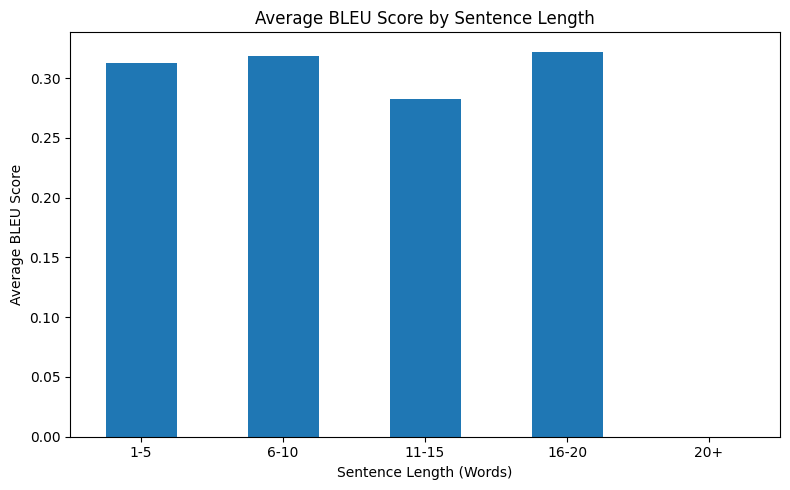

In [56]:
smooth = SmoothingFunction().method1

# Creating Evaluation dataframe
results = pd.DataFrame({
    'English': x_test_sample.tolist(),
    'Actual Spanish': actual_translations,
    'Predicted Spanish': predictions
})

# Calculating sentence-level BLEU
results['BLEU'] = [
    sentence_bleu(
        [actual.lower().split()],
        predicted.lower().split(),
        smoothing_function=smooth
    )
    for actual, predicted in zip(actual_translations, predictions)
]

# Calculating sentence lengths
results['English Length'] = results['English'].apply(lambda x: len(x.split()))
results['Spanish Length'] = results['Actual Spanish'].apply(lambda x: len(x.split()))

# Display best translations
print("BEST TRANSLATIONS:")
display(results.sort_values('BLEU', ascending=False).head(10))

# Display worst translations
print("\nWORST TRANSLATIONS:")
display(results.sort_values('BLEU').head(10))

# Group sentences by length
results['Length Group'] = pd.cut(
    results['English Length'],
    bins=[0, 5, 10, 15, 20, float('inf')],
    labels=['1-5', '6-10', '11-15', '16-20', '20+']
)

# Calculating average BLEU for each sentence-length group
length_analysis = results.groupby(
    'Length Group', observed=False
)['BLEU'].mean()

# Plot average BLEU by sentence length
length_analysis.plot(kind='bar', figsize=(8, 5))

plt.title('Average BLEU Score by Sentence Length')
plt.xlabel('Sentence Length (Words)')
plt.ylabel('Average BLEU Score')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### **User-Friendly English-to-Spanish Translator**

In [ ]:
print("=" * 50)
print("       ENGLISH → ESPAÑA TRANSLATOR  ")
print("=" * 50)
print("Enter an English sentence for Spanish translation")
print("Type 'exit' to quit.\n")

while True:
    sentence = input("Enter English sentence: ").strip()

    if sentence.lower() == 'exit':
        print("\nThank you for using the translator!")
        break

    if not sentence:
        print("Please enter a valid sentence.\n")
        continue

    translation = translate(sentence)

    print("-" * 50)
    print("Spanish Translation:", translation)
    print("-" * 50, "\n")

       ENGLISH → ESPAÑA TRANSLATOR  
Enter an English sentence for Spanish translation
Type 'exit' to quit.

Enter English sentence: I love football and watching movies.
--------------------------------------------------
Spanish Translation: me encanta jugar y ver la vista
-------------------------------------------------- 

Enter English sentence: He is a great man
--------------------------------------------------
Spanish Translation: el es un hombre genial
-------------------------------------------------- 

Enter English sentence: They are good friends
--------------------------------------------------
Spanish Translation: son buenos amigos
-------------------------------------------------- 

Enter English sentence: She is a very kind woman
--------------------------------------------------
Spanish Translation: ella es una mujer muy amable
-------------------------------------------------- 




# **Project Summary**

This project builds an **English-to-Spanish Neural Machine Translation System using Deep Learning**. It uses a Sequence-to-Sequence (Seq2Seq) architecture with a Bidirectional LSTM encoder, an LSTM decoder, and an Attention mechanism to translate English sentences into Spanish.

The model learns from paired English and Spanish sentences and generates translations one word at a time. The project also includes translation evaluation using Exact Match Accuracy and BLEU Score.

## **Dataset Overview**

The project uses the `english-spanish-dataset.csv` dataset, containing **120,614 rows and 3 columns** initially.

The relevant columns are:
- **English:** Input sentences provided to the encoder.
- **Spanish:** Target translations generated by the decoder.

The dataset is checked for missing values and duplicates. Empty sentences are removed, text is cleaned, and duplicate sentence pairs identified after cleaning are removed.

## **Project Workflow**

### **1. Data Cleaning**

A custom `clean_text()` function is applied to both languages.

- Normalizes Unicode characters while preserving Spanish accents.
- Removes leading and trailing spaces.
- Replaces multiple spaces, tabs, and newlines with a single space.
- Removes empty English and Spanish sentences.
- Removes duplicate sentence pairs.

### **2. Exploratory Data Analysis (EDA)**

EDA is performed to understand the sentence distributions and frequently occurring words in both languages.

- English sentence length distribution
- Spanish sentence length distribution
- English word cloud visualization
- Spanish word cloud visualization
- English and Spanish word count analysis

### **3. Data Preparation**

The dataset is divided into training and testing sets using an 80/20 ratio, with `random_state=42`.

- Training samples: 96,269
- Testing samples: 24,068

Separate tokenizers are created for English and Spanish to convert words into numerical sequences.

Special tokens are introduced for Spanish translation:

- `<start>` — Indicates the beginning of a Spanish sentence.
- `<end>` — Indicates the end of a Spanish sentence.
- `<unk>` — Represents out-of-vocabulary words.

Teacher forcing is used by shifting the Spanish target sequence to create decoder inputs and expected outputs.

Sequences are padded to fixed lengths:

- English maximum sequence length: 47
- Spanish maximum sequence length: 50
- English vocabulary size: 12,451
- Spanish vocabulary size: 22,737

### **4. Encoder Architecture**

The encoder processes English input sentences and converts them into contextual representations.

It consists of:

- **Embedding Layer:** Converts English word IDs into 128-dimensional vectors.
- **Bidirectional LSTM:** Uses 128 units in each direction to capture information from forward and backward contexts.
- **Encoder States:** Combines forward and backward hidden and cell states to initialize the decoder.

### **5. Decoder Architecture**

The decoder generates Spanish translations using the encoder's contextual information.

It consists of:

- **Embedding Layer:** Converts Spanish token IDs into 128-dimensional vectors.
- **LSTM Layer:** Uses 256 units and receives the encoder's final states as its initial states.
- **Attention Mechanism:** Helps the decoder focus on relevant English input positions while generating Spanish words.
- **Dense Output Layer:** Uses Softmax activation to predict probabilities across the Spanish vocabulary.

### **6. Model Training**

The complete encoder-decoder model is trained using:

- **Optimizer:** Adam
- **Loss Function:** Sparse Categorical Crossentropy
- **Batch Size:** 128
- **Maximum Epochs:** 30
- **Validation Split:** 10%

Padding tokens are assigned zero sample weight so they do not contribute to the training loss.

Two callbacks are implemented:

- **EarlyStopping:** Stops training when validation loss stops improving and restores the best model weights.
- **ReduceLROnPlateau:** Reduces the learning rate when validation loss stops improving.

### **7. Translation System**

Separate encoder and decoder inference models are created to generate translations one token at a time.

A custom `translate()` function:

1. Accepts an English sentence.
2. Converts it into a numerical sequence.
3. Passes the input through the trained encoder.
4. Initializes the decoder with the encoder states and Spanish `<start>` token.
5. Predicts Spanish words sequentially using the decoder and attention mechanism.
6. Stops when the `<end>` token is generated or the maximum sequence length is reached.
7. Returns the generated Spanish translation.

### **8. Model Evaluation and Error Analysis**

The model is evaluated on a sample of **500 test sentences** using:

- **Test Loss:** Measures the model's prediction error.
- **Exact Match Accuracy:** Measures the percentage of translations that exactly match the reference after text normalization.
- **BLEU Score:** Measures the similarity between generated translations and reference translations based on overlapping word sequences.

The project also includes:
- Comparison of actual and predicted Spanish translations.
- Identification of the best and worst translations using sentence-level BLEU scores.
- Analysis of average BLEU scores across different English sentence-length groups.

## **Model Performance**

| Evaluation Metric | Result |
|---|---:|
| Test Loss | 1.9965 |
| Exact Match Accuracy | 15.80% |
| BLEU Score | 0.357 |


These results are calculated using a sample of 500 test sentences, rather than the complete test set.

The translation examples show that the model can generate accurate translations for some sentences, while others contain word-choice, grammar, or sentence-structure errors.

## **Conclusion**

This project demonstrates how **Sequence-to-Sequence Learning, Bidirectional LSTMs, and Attention Mechanisms** can be combined to build a neural machine translation system.

The encoder captures contextual information from English sentences, while the decoder generates Spanish translations step by step. The attention mechanism helps the decoder focus on relevant parts of the input sentence during translation.

The project also provides practical experience with NLP preprocessing, tokenization, sequence padding, teacher forcing, deep learning model training, inference, BLEU evaluation, and translation error analysis.





---

## **Author**

**Created by Hashir Khan**

If you found this project useful, feel free to drop a star on this repository & explore my other projects and repositories on GitHub.

🔗 **Explore all my GitHub repositories:**  
[GitHub - Hashir Khan](https://github.com/Beinghash?tab=repositories)

---
